# Anime Recommendation System using Cosine Similarity
### Content-based recommendations from genre, type, episodes, rating and popularity

---

## 1. Objective
Build a **content-based recommendation system** on an anime dataset: given a target anime, return a ranked list of similar anime using **cosine similarity**. 

**Plan**
1. Load, clean and explore the data
2. Feature extraction — encode genres and type, normalise numeric features
3. Recommendation function (top-N and similarity-threshold based)
4. Experiment with similarity thresholds
5. Evaluate the system and identify improvements
6. Interview questions

**Data dictionary**

| Column | Meaning |
|---|---|
| `anime_id` | Unique id of the anime |
| `name` | Anime title |
| `genre` | Comma-separated list of genres |
| `type` | Broadcast type (TV, Movie, OVA, Special, ONA, Music) |
| `episodes` | Number of episodes |
| `rating` | Average user rating (out of 10) |
| `members` | Number of community members who added the anime (a popularity measure) |

## 2. Setup

In [1]:
import warnings, html, re
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from difflib import get_close_matches

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.metrics.pairwise import cosine_similarity

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42
rng = np.random.RandomState(RANDOM_STATE)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

## 3. Data preprocessing
### 3.1 Load the data

In [2]:
df_raw = pd.read_csv("anime.csv")
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (12294, 7)


,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Military, Shounen",TV,64,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, Sci-Fi, Sho...",TV,51,9.25,114262
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24,9.17,673572
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, Sci-Fi, Sho...",TV,51,9.16,151266


### 3.2 Understand the structure

In [3]:
df_raw.info()
print("\nMissing values:\n", df_raw.isna().sum())
print("\nDuplicate rows:", df_raw.duplicated().sum(), "| duplicate ids:", df_raw["anime_id"].duplicated().sum(),
      "| duplicate titles:", df_raw["name"].duplicated().sum())
print("\nEpisodes stored as text; non-numeric values:", df_raw.loc[pd.to_numeric(df_raw["episodes"], errors="coerce").isna(), "episodes"].unique())
print("Titles containing HTML entities (e.g. &#039;):", df_raw["name"].str.contains(r"&#?\w+;").sum())
df_raw.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 12294 entries, 0 to 12293
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   anime_id  12294 non-null  int64  
 1   name      12294 non-null  str    
 2   genre     12232 non-null  str    
 3   type      12269 non-null  str    
 4   episodes  12294 non-null  str    
 5   rating    12064 non-null  float64
 6   members   12294 non-null  int64  
dtypes: float64(1), int64(2), str(4)
memory usage: 672.5 KB

Missing values:
 anime_id      0
name          0
genre        62
type         25
episodes      0
rating      230
members       0
dtype: int64

Duplicate rows: 0 | duplicate ids: 0 | duplicate titles: 2

Episodes stored as text; non-numeric values: <StringArray>
['Unknown']
Length: 1, dtype: str
Titles containing HTML entities (e.g. &#039;): 292


,count,mean,std,min,25%,50%,75%,max
anime_id,12294.0,14058.221653,11455.294701,1.00,3484.25,10260.50,24794.50,34527.0
rating,12064.0,6.473902,1.026746,1.67,5.88,6.57,7.18,10.0
members,12294.0,18071.338864,54820.676925,5.00,225.00,1550.00,9437.00,1013917.0


**Observations**
- `genre` (62), `type` (25) and `rating` (230) have missing values.
- `episodes` is stored as text because 340 rows contain the string `"Unknown"`.
- Some titles contain HTML entities (e.g. `Gintama&#039;`) that should be decoded.
- There are no duplicate ids or rows. Two titles appear twice but have different ids (different anime sharing a name), so they are kept.

### 3.3 Handle missing values and clean the data
| Issue | Treatment | Reason |
|---|---|---|
| Missing `genre` (62 rows, 0.5 %) | **Drop** | Genre is the main similarity signal; with none, the anime cannot be placed meaningfully |
| Missing `type` (25 rows) | Fill with `"Unknown"` | Keeps the rows; they just form their own type category |
| `episodes` = `"Unknown"` (340 rows) | Convert to number, fill with the **median of the anime's type** | Episode counts differ hugely by type (a Movie is ~1 episode, a TV series is ~12–25) |
| Missing `rating` (230 rows) | Fill with the **median rating of the anime's type** | Median is robust to outliers; these are mostly unrated, low-popularity titles |
| HTML entities in `name` | Decode with `html.unescape` | Clean, searchable titles |

In [4]:
df = df_raw.copy()

# 1) Decode HTML entities in titles
df["name"] = df["name"].apply(html.unescape)

# 2) Drop rows without genre (cannot be used for content-based similarity)
n_before = len(df)
df = df.dropna(subset=["genre"]).reset_index(drop=True)
print(f"Dropped {n_before - len(df)} rows with missing genre")

# 3) Missing type -> 'Unknown'
df["type"] = df["type"].fillna("Unknown")

# 4) Episodes: text -> numeric ('Unknown' -> NaN), then impute with the median per type
df["episodes"] = pd.to_numeric(df["episodes"], errors="coerce")
df["episodes"] = df["episodes"].fillna(df.groupby("type")["episodes"].transform("median"))
df["episodes"] = df["episodes"].fillna(df["episodes"].median())   # safety net for the 'Unknown' type

# 5) Rating: impute with the median rating of the anime's type
df["rating"] = df["rating"].fillna(df.groupby("type")["rating"].transform("median"))
df["rating"] = df["rating"].fillna(df["rating"].median())

print("Remaining missing values:", int(df.isna().sum().sum()))
print("Final shape:", df.shape)
df.head()

Dropped 62 rows with missing genre
Remaining missing values: 0
Final shape: (12232, 7)


,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1.0,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Military, Shounen",TV,64.0,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, Sci-Fi, Sho...",TV,51.0,9.25,114262
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24.0,9.17,673572
4,9969,Gintama',"Action, Comedy, Historical, Parody, Samurai, Sci-Fi, Sho...",TV,51.0,9.16,151266


## 4. Exploratory data analysis

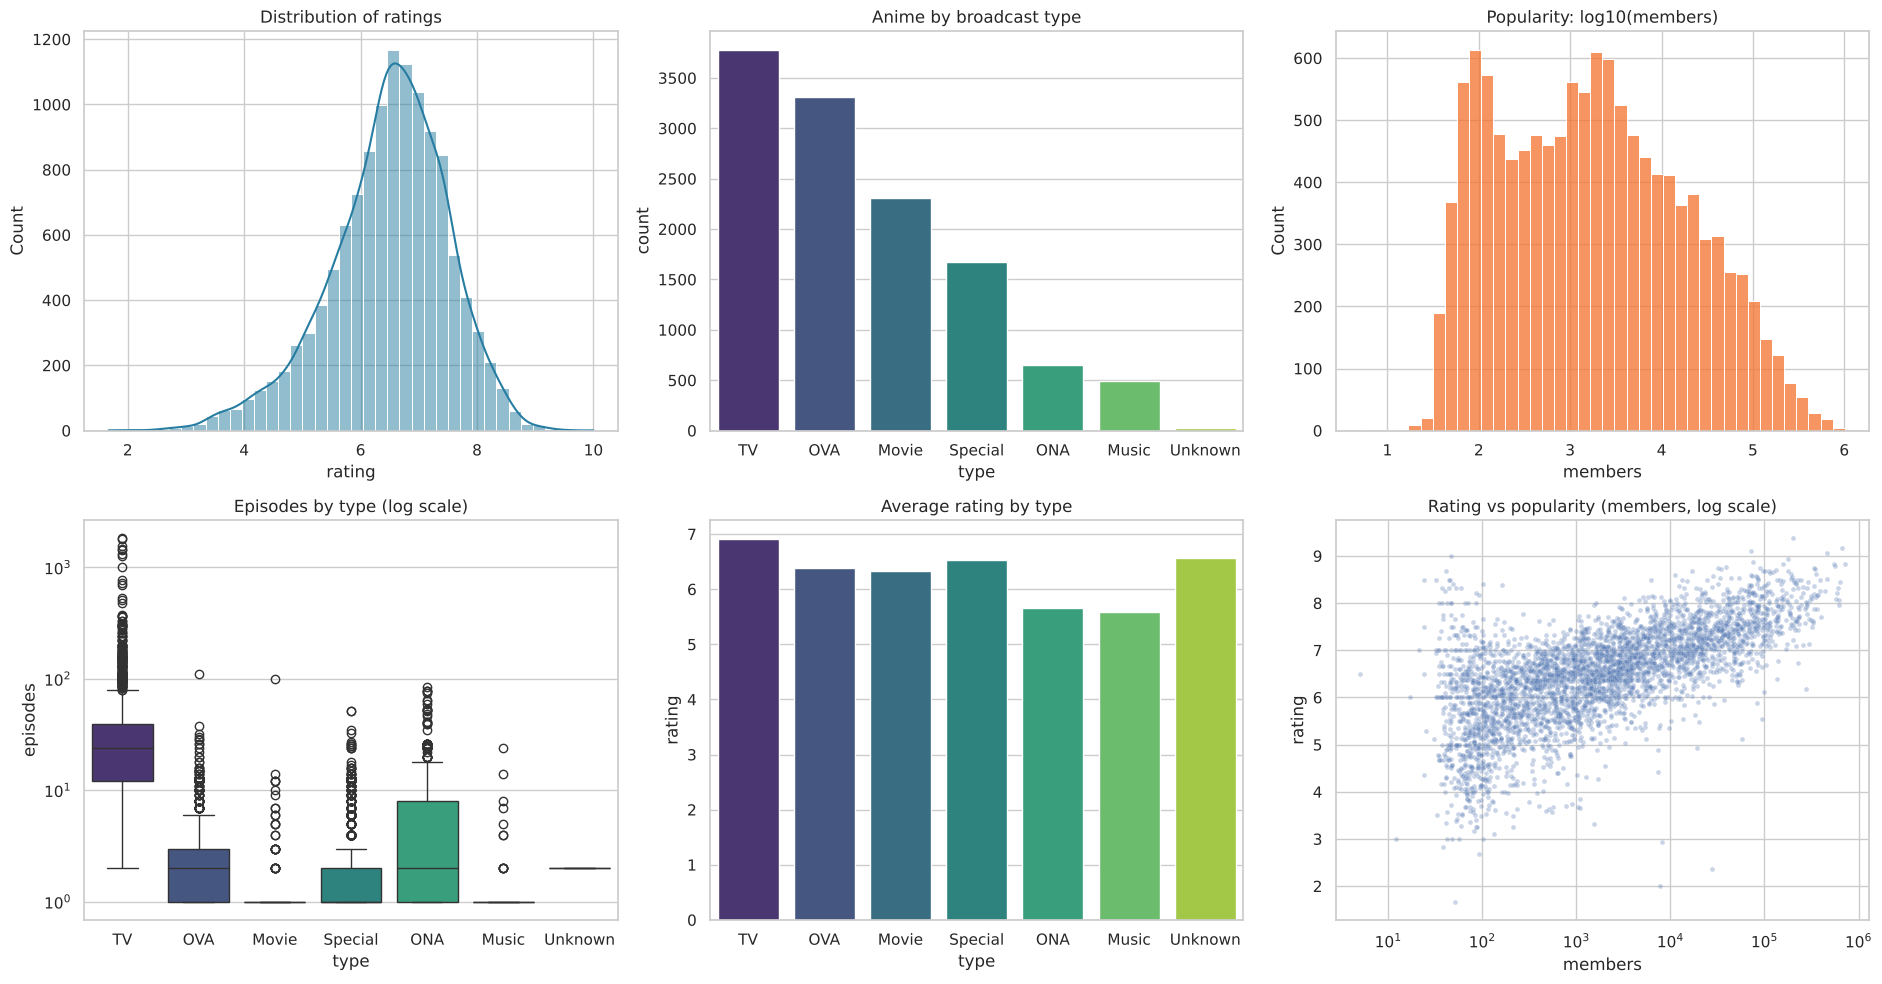

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(19, 10))

# Rating distribution
sns.histplot(df["rating"], bins=40, kde=True, ax=axes[0, 0], color="#277da1")
axes[0, 0].set_title("Distribution of ratings")

# Type counts
order = df["type"].value_counts().index
sns.countplot(data=df, x="type", order=order, ax=axes[0, 1], palette="viridis")
axes[0, 1].set_title("Anime by broadcast type")

# Members (popularity) on a log scale
sns.histplot(np.log10(df["members"]), bins=40, ax=axes[0, 2], color="#f3722c")
axes[0, 2].set_title("Popularity: log10(members)")

# Episodes by type (log scale because of extreme values)
sns.boxplot(data=df, x="type", y="episodes", order=order, ax=axes[1, 0], palette="viridis")
axes[1, 0].set_yscale("log"); axes[1, 0].set_title("Episodes by type (log scale)")

# Mean rating by type
sns.barplot(data=df, x="type", y="rating", order=order, ax=axes[1, 1], palette="viridis", errorbar=None)
axes[1, 1].set_title("Average rating by type")

# Rating vs popularity
sns.scatterplot(data=df.sample(4000, random_state=RANDOM_STATE), x="members", y="rating", alpha=0.3, s=12, ax=axes[1, 2])
axes[1, 2].set_xscale("log"); axes[1, 2].set_title("Rating vs popularity (members, log scale)")
plt.tight_layout(); plt.show()

Number of distinct genres: 43
Genres per anime: mean = 3.0, max = 13


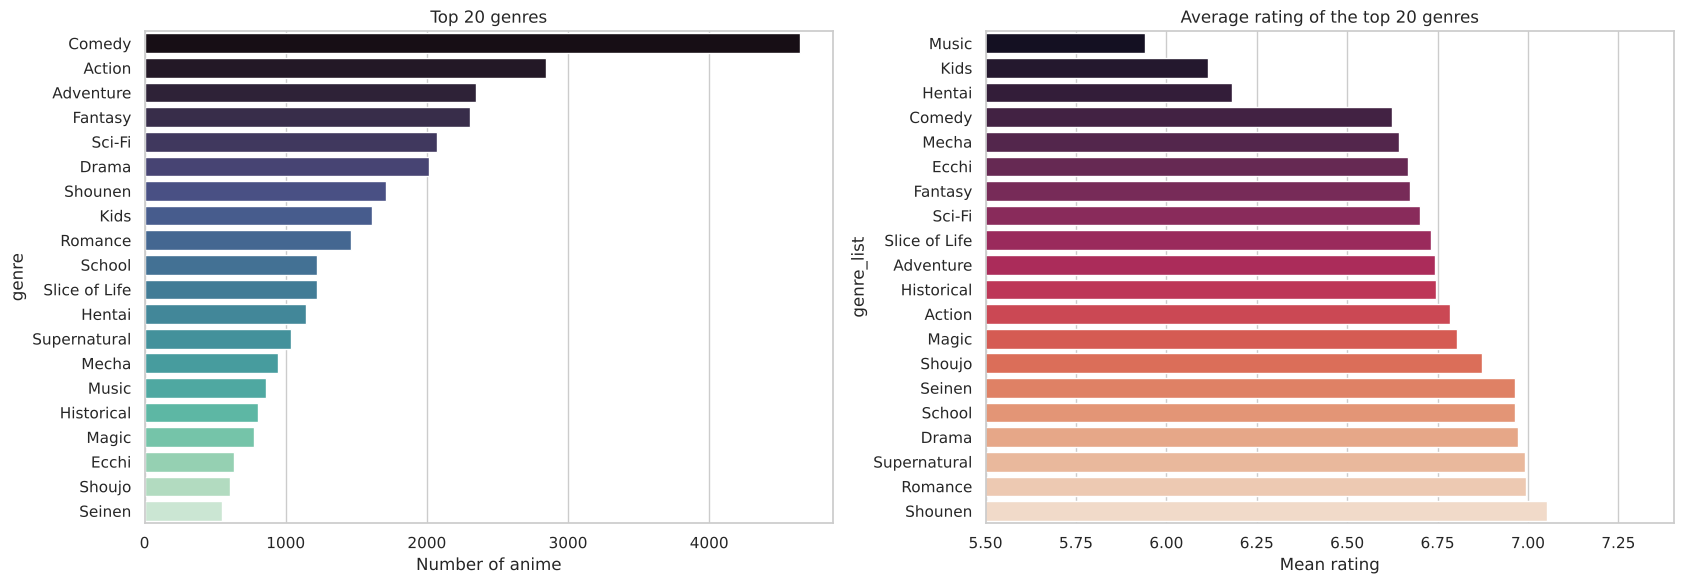

In [6]:
# Genre analysis: split the comma-separated string into individual genres
genre_lists = df["genre"].str.split(",").apply(lambda g: [x.strip() for x in g])
genre_counts = genre_lists.explode().value_counts()
print("Number of distinct genres:", genre_counts.size)
print("Genres per anime: mean = %.1f, max = %d" % (genre_lists.str.len().mean(), genre_lists.str.len().max()))

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.barplot(x=genre_counts.head(20).values, y=genre_counts.head(20).index, ax=axes[0], palette="mako")
axes[0].set_title("Top 20 genres"); axes[0].set_xlabel("Number of anime")

# Average rating of the 20 most frequent genres
g_exploded = df.assign(genre_list=genre_lists).explode("genre_list")
top_g = genre_counts.head(20).index
avg_rating = g_exploded[g_exploded["genre_list"].isin(top_g)].groupby("genre_list")["rating"].mean().sort_values()
sns.barplot(x=avg_rating.values, y=avg_rating.index, ax=axes[1], palette="rocket")
axes[1].set_xlim(5.5, None); axes[1].set_title("Average rating of the top 20 genres"); axes[1].set_xlabel("Mean rating")
plt.tight_layout(); plt.show()

,name,type,episodes,rating,members
0,Kimi no Na wa.,Movie,1.0,9.37,200630
1,Fullmetal Alchemist: Brotherhood,TV,64.0,9.26,793665
2,Gintama°,TV,51.0,9.25,114262
3,Steins;Gate,TV,24.0,9.17,673572
4,Gintama',TV,51.0,9.16,151266
5,Haikyuu!!: Karasuno Koukou VS Shiratorizawa Gakuen Koukou,TV,10.0,9.15,93351
6,Hunter x Hunter (2011),TV,148.0,9.13,425855
7,Ginga Eiyuu Densetsu,OVA,110.0,9.11,80679
9,Gintama': Enchousen,TV,13.0,9.11,81109
8,Gintama Movie: Kanketsu-hen - Yorozuya yo Eien Nare,Movie,1.0,9.10,72534


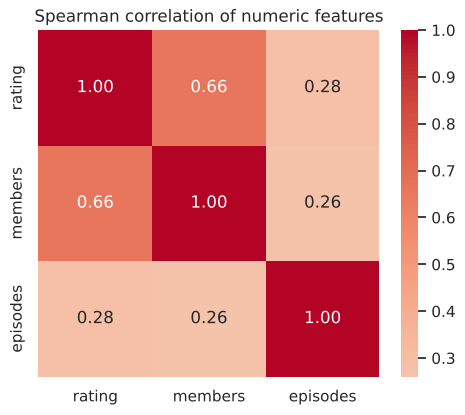

In [7]:
# Top 10 highest rated anime with a meaningful audience (>= 50,000 members) and a numeric correlation check
display(df[df["members"] >= 50000].nlargest(10, "rating")[["name", "type", "episodes", "rating", "members"]])

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(df[["rating", "members", "episodes"]].corr(method="spearman"), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Spearman correlation of numeric features"); plt.show()

**Insights from the EDA**
- **Ratings** are left-skewed (mean ≈ 6.5, median 6.6, range 1.7–10): most anime are rated between 5.9 and 7.2, and very high ratings are rare.
- **Type mix:** TV (31 %), OVA (27 %) and Movie (19 %) dominate. TV series are rated highest on average (≈ 6.9) and have a median of 24 episodes, while Movies, Specials and Music videos are essentially single-episode releases.
- **Popularity is extremely skewed:** the median anime has only ~1,550 members, and 43 % have fewer than 1,000, while a small elite has hundreds of thousands. Only 1,134 titles have ≥ 50,000 members. This is why `members` is log-transformed.
- **Genres:** 43 distinct genres, ~3 per anime. Comedy, Action, Adventure, Fantasy and Sci-Fi are the most common. Shounen, Supernatural, Romance and Drama have the highest average ratings (≈ 7.0), while Music, Kids and Hentai have the lowest (≈ 5.9–6.2).
- **Rating and popularity move together** (Spearman ρ ≈ 0.67): well-rated anime attract more members. Episodes are only weakly related to either (ρ ≈ 0.3).

## 5. Feature extraction
We build a content representation of each anime from four ingredients:

| Feature | Encoding | Why |
|---|---|---|
| `genre` | **Multi-hot** vector (one column per genre, via `CountVectorizer`) | Genre is the strongest signal of "similar content"; an anime can have many genres |
| `type` | **One-hot** | A 1-episode Movie is a different experience from a 24-episode TV series |
| `rating` | **Min-Max** scaled to [0, 1] | Recommends anime of similar quality |
| `members`, `episodes` | **log1p**, then Min-Max scaled | Both are extremely right-skewed; the log transform stops a few giants from dominating |

Cosine similarity measures the **angle** between two feature vectors (1 = same direction, 0 = nothing in common) and is the standard choice for multi-hot content features because it ignores vector length. Each block gets a **weight** so we can control how much each ingredient matters; the weights are tuned in section 8.

In [8]:
# --- Genre: multi-hot encoding. A custom tokenizer splits on commas so multi-word genres stay intact ("Slice of Life")
genre_vec = CountVectorizer(tokenizer=lambda s: [g.strip() for g in s.split(",")],
                            lowercase=False, binary=True, token_pattern=None)
G = genre_vec.fit_transform(df["genre"]).toarray().astype(np.float32)
genre_names = genre_vec.get_feature_names_out()

# --- TF-IDF variant of the genre block (rare genres get more weight) - compared later
genre_tfidf = TfidfVectorizer(tokenizer=lambda s: [g.strip() for g in s.split(",")],
                              lowercase=False, token_pattern=None)
G_tfidf = genre_tfidf.fit_transform(df["genre"]).toarray().astype(np.float32)

# --- Type: one-hot encoding
T = OneHotEncoder(sparse_output=False).fit_transform(df[["type"]]).astype(np.float32)

# --- Numeric features: log-transform the skewed ones, then scale everything to [0, 1]
num = pd.DataFrame({
    "rating": df["rating"],
    "log_members": np.log1p(df["members"]),
    "log_episodes": np.log1p(df["episodes"]),
})
N = MinMaxScaler().fit_transform(num).astype(np.float32)

print(f"Genre matrix : {G.shape}  ({len(genre_names)} genres)")
print(f"Type matrix  : {T.shape}")
print(f"Numeric block: {N.shape}  columns = {list(num.columns)}")

Genre matrix : (12232, 43)  (43 genres)
Type matrix  : (12232, 7)
Numeric block: (12232, 3)  columns = ['rating', 'log_members', 'log_episodes']


## 6. Recommendation system
### 6.1 Building the combined feature matrix
`build_features` stacks the weighted blocks into one matrix. Because cosine similarity is scale-sensitive *between* blocks, the weights decide how much each block contributes to the final score.

In [9]:
def build_features(w_genre=1.0, w_type=0.0, w_rating=0.0, w_members=0.0, w_episodes=0.0, tfidf=False):
    """Stack the weighted feature blocks into a single item x feature matrix."""
    blocks = [w_genre * (G_tfidf if tfidf else G)]
    if w_type:     blocks.append(w_type * T)
    if w_rating:   blocks.append(w_rating * N[:, [0]])
    if w_members:  blocks.append(w_members * N[:, [1]])
    if w_episodes: blocks.append(w_episodes * N[:, [2]])
    return np.hstack(blocks).astype(np.float32)

# Initial (default) configuration; refined by the experiments in section 8
FEATURE_WEIGHTS = dict(w_genre=1.0, w_type=0.5, w_rating=0.5, w_members=0.25, w_episodes=0.25)
X = build_features(**FEATURE_WEIGHTS)
print("Feature matrix shape:", X.shape)

Feature matrix shape: (12232, 53)


### 6.2 The recommendation function
`recommend()`:
1. finds the target anime (exact match first, then **fuzzy matching** so small typos or partial titles still work),
2. computes the cosine similarity between the target and *all* anime (on demand — a full 12k × 12k matrix would need ~600 MB),
3. removes the target itself, keeps only anime with `similarity >= threshold`, and returns the `top_n` best.

In [10]:
# Lookup helpers --------------------------------------------------------------
title_lookup = {t.lower(): i for i, t in enumerate(df["name"])}   # lower-cased title -> row index
# if two anime share a title, keep the more popular one
for i in df.sort_values("members").index:
    title_lookup[df.at[i, "name"].lower()] = i

def find_anime(title):
    """Return the row index of the best matching title (exact, then substring, then fuzzy)."""
    key = title.strip().lower()
    if key in title_lookup:
        return title_lookup[key]
    # substring match -> choose the most popular candidate
    cand = df[df["name"].str.lower().str.contains(re.escape(key), na=False)]
    if len(cand):
        return cand["members"].idxmax()
    close = get_close_matches(key, title_lookup.keys(), n=1, cutoff=0.6)
    if close:
        return title_lookup[close[0]]
    raise ValueError(f"No anime found matching '{title}'")

def recommend(title, top_n=10, threshold=0.0, features=None):
    """
    Recommend anime similar to `title` using cosine similarity.

    Parameters
    ----------
    title     : name of the target anime (typos / partial names are tolerated)
    top_n     : maximum number of recommendations to return
    threshold : only keep anime with cosine similarity >= threshold (0-1)
    features  : optional feature matrix (defaults to the global X)
    """
    features = X if features is None else features
    idx = find_anime(title)
    sims = cosine_similarity(features[idx].reshape(1, -1), features).ravel()
    sims[idx] = -1                                    # never recommend the target itself
    order = np.argsort(-sims)
    order = [i for i in order if sims[i] >= threshold][:top_n]
    out = df.loc[order, ["name", "genre", "type", "episodes", "rating", "members"]].copy()
    out.insert(1, "similarity", sims[order].round(4))
    out.attrs["target"] = df.at[idx, "name"]
    return out.reset_index(drop=True)

# Demo ---------------------------------------------------------------------------
t = find_anime("Naruto")
print("Target:", df.at[t, "name"], "|", df.at[t, "genre"], "|", df.at[t, "type"], "| rating", df.at[t, "rating"])
recommend("Naruto", top_n=10)

Target: Naruto | Action, Comedy, Martial Arts, Shounen, Super Power | TV | rating 7.81


,name,similarity,genre,type,episodes,rating,members
0,Naruto: Shippuuden,0.9994,"Action, Comedy, Martial Arts, Shounen, Super Power",TV,24.0,7.94,533578
1,Boruto: Naruto the Movie,0.9512,"Action, Comedy, Martial Arts, Shounen, Super Power",Movie,1.0,8.03,74690
2,Naruto: Shippuuden Movie 4 - The Lost Tower,0.9512,"Action, Comedy, Martial Arts, Shounen, Super Power",Movie,1.0,7.53,84527
3,Naruto: Shippuuden Movie 3 - Hi no Ishi wo Tsugu Mono,0.9511,"Action, Comedy, Martial Arts, Shounen, Super Power",Movie,1.0,7.50,83515
4,Naruto x UT,0.9509,"Action, Comedy, Martial Arts, Shounen, Super Power",OVA,1.0,7.58,23465
5,Boruto: Naruto the Movie - Naruto ga Hokage ni Natta Hi,0.9508,"Action, Comedy, Martial Arts, Shounen, Super Power",Special,1.0,7.68,16868
6,Naruto Soyokazeden Movie: Naruto to Mashin to Mitsu no O...,0.9507,"Action, Comedy, Martial Arts, Shounen, Super Power",Movie,1.0,7.11,25174
7,Naruto Shippuuden: Sunny Side Battle,0.9505,"Action, Comedy, Martial Arts, Shounen, Super Power",Special,1.0,7.26,13014
8,Katekyo Hitman Reborn!,0.9039,"Action, Comedy, Shounen, Super Power",TV,203.0,8.37,258103
9,Dragon Ball Z,0.8562,"Action, Adventure, Comedy, Fantasy, Martial Arts, Shoune...",TV,291.0,8.32,375662


In [11]:
# More examples across different kinds of titles (also shows the fuzzy title search: 'steins gate' without punctuation)
for q in ["Death Note", "steins gate", "Kimi no Na wa."]:
    r = recommend(q, top_n=5)
    print(f"\n=== Because you liked: {r.attrs['target']} ===")
    display(r[["name", "similarity", "genre", "type", "episodes", "rating"]])


=== Because you liked: Death Note ===


,name,similarity,genre,type,episodes,rating
0,Death Note Rewrite,0.9530,"Mystery, Police, Psychological, Supernatural, Thriller",Special,2.0,7.84
1,Mousou Dairinin,0.9185,"Drama, Mystery, Police, Psychological, Supernatural, Thr...",TV,13.0,7.74
2,Higurashi no Naku Koro ni Kai,0.9044,"Mystery, Psychological, Supernatural, Thriller",TV,24.0,8.41
3,Higurashi no Naku Koro ni,0.8175,"Horror, Mystery, Psychological, Supernatural, Thriller",TV,26.0,8.17
4,Jigoku Shoujo Mitsuganae,0.7971,"Mystery, Psychological, Supernatural",TV,26.0,7.81



=== Because you liked: Steins;Gate ===


,name,similarity,genre,type,episodes,rating
0,Steins;Gate Movie: Fuka Ryouiki no Déjà vu,0.8978,"Sci-Fi, Thriller",Movie,1.0,8.61
1,Steins;Gate: Oukoubakko no Poriomania,0.8974,"Sci-Fi, Thriller",Special,1.0,8.46
2,Steins;Gate: Kyoukaimenjou no Missing Link - Divide By Zero,0.8964,"Sci-Fi, Thriller",Special,1.0,8.34
3,Steins;Gate 0,0.8915,"Sci-Fi, Thriller",Unknown,2.0,6.57
4,Fireball Charming,0.7700,Sci-Fi,TV,13.0,6.94



=== Because you liked: Kimi no Na wa. ===


,name,similarity,genre,type,episodes,rating
0,Wind: A Breath of Heart OVA,0.9389,"Drama, Romance, School, Supernatural",OVA,3.0,6.35
1,Wind: A Breath of Heart (TV),0.9384,"Drama, Romance, School, Supernatural",TV,13.0,6.14
2,Aura: Maryuuin Kouga Saigo no Tatakai,0.9016,"Comedy, Drama, Romance, School, Supernatural",Movie,1.0,7.67
3,Kokoro ga Sakebitagatterunda.,0.8817,"Drama, Romance, School",Movie,1.0,8.32
4,Harmonie,0.8805,"Drama, School, Supernatural",Movie,1.0,7.52


## 7. Experimenting with similarity thresholds
The `threshold` controls how strict the system is: a high value returns only near-identical anime (short list, high precision); a low value returns a long list of looser matches. We count how many anime pass each threshold for several targets and then inspect the resulting lists.

,>= 0.5,>= 0.6,>= 0.7,>= 0.8,>= 0.85,>= 0.9,>= 0.95,>= 0.99
target,,,,,,,,
Naruto,985,346,129,34,16,9,8,1
Fullmetal Alchemist: Brotherhood,1176,395,94,25,10,2,0,0
Death Note,119,43,18,4,3,3,1,0
Steins;Gate,142,53,13,4,4,0,0,0
Kimi no Na wa.,500,207,79,23,6,3,0,0
One Piece,1743,752,208,64,38,4,3,0


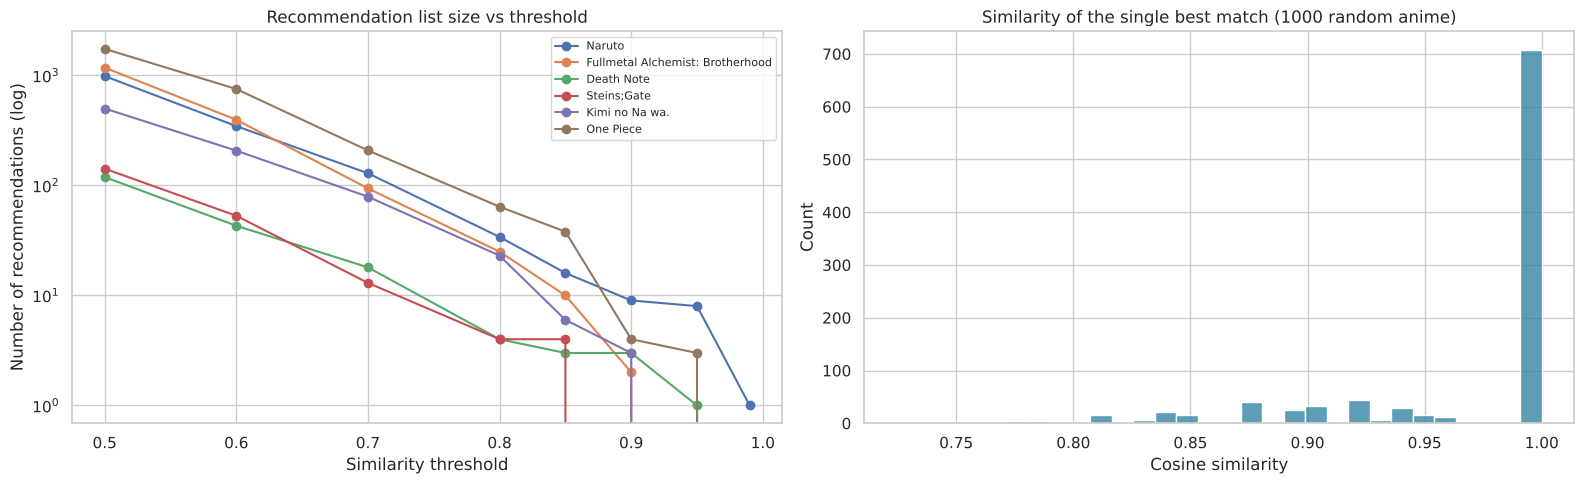

In [12]:
targets = ["Naruto", "Fullmetal Alchemist: Brotherhood", "Death Note", "Steins;Gate", "Kimi no Na wa.", "One Piece"]
thresholds = [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 0.99]

rows = []
for tname in targets:
    idx = find_anime(tname)
    sims = cosine_similarity(X[idx].reshape(1, -1), X).ravel(); sims[idx] = -1
    rows.append({"target": df.at[idx, "name"], **{f">= {th}": int((sims >= th).sum()) for th in thresholds}})
thr_table = pd.DataFrame(rows).set_index("target")
display(thr_table)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for tname, row in thr_table.iterrows():
    axes[0].plot(thresholds, row.values, marker="o", label=tname)
axes[0].set_yscale("log"); axes[0].set_xlabel("Similarity threshold"); axes[0].set_ylabel("Number of recommendations (log)")
axes[0].set_title("Recommendation list size vs threshold"); axes[0].legend(fontsize=8)

# Distribution of the best-match similarity over 1000 random anime
sample_idx = rng.choice(len(df), 1000, replace=False)
top1 = [np.sort(cosine_similarity(X[i].reshape(1, -1), X).ravel())[-2] for i in sample_idx]   # [-2] skips the item itself
sns.histplot(top1, bins=30, ax=axes[1], color="#277da1")
axes[1].set_title("Similarity of the single best match (1000 random anime)"); axes[1].set_xlabel("Cosine similarity")
plt.tight_layout(); plt.show()

In [13]:
# What does a threshold change look like for a single title?
for th in [0.0, 0.9, 0.97]:
    r = recommend("Death Note", top_n=8, threshold=th)
    print(f"\n--- Death Note | threshold = {th} | {len(r)} recommendations returned (max 8) ---")
    display(r[["name", "similarity", "genre", "type", "episodes", "rating"]])


--- Death Note | threshold = 0.0 | 8 recommendations returned (max 8) ---


,name,similarity,genre,type,episodes,rating
0,Death Note Rewrite,0.9530,"Mystery, Police, Psychological, Supernatural, Thriller",Special,2.0,7.84
1,Mousou Dairinin,0.9185,"Drama, Mystery, Police, Psychological, Supernatural, Thr...",TV,13.0,7.74
2,Higurashi no Naku Koro ni Kai,0.9044,"Mystery, Psychological, Supernatural, Thriller",TV,24.0,8.41
3,Higurashi no Naku Koro ni,0.8175,"Horror, Mystery, Psychological, Supernatural, Thriller",TV,26.0,8.17
4,Jigoku Shoujo Mitsuganae,0.7971,"Mystery, Psychological, Supernatural",TV,26.0,7.81
5,Yakushiji Ryouko no Kaiki Jikenbo,0.7958,"Mystery, Police, Supernatural",TV,13.0,7.19
6,Saint Luminous Jogakuin,0.7931,"Mystery, Psychological, Supernatural",TV,13.0,6.17
7,Higurashi no Naku Koro ni Rei,0.7700,"Comedy, Mystery, Psychological, Supernatural, Thriller",OVA,5.0,7.56



--- Death Note | threshold = 0.9 | 3 recommendations returned (max 8) ---


,name,similarity,genre,type,episodes,rating
0,Death Note Rewrite,0.9530,"Mystery, Police, Psychological, Supernatural, Thriller",Special,2.0,7.84
1,Mousou Dairinin,0.9185,"Drama, Mystery, Police, Psychological, Supernatural, Thr...",TV,13.0,7.74
2,Higurashi no Naku Koro ni Kai,0.9044,"Mystery, Psychological, Supernatural, Thriller",TV,24.0,8.41



--- Death Note | threshold = 0.97 | 0 recommendations returned (max 8) ---


,name,similarity,genre,type,episodes,rating


**Observations**
- The number of qualifying anime falls steeply as the threshold rises: e.g. *Naruto* has ≈ 985 anime with similarity ≥ 0.5 but only 9 at ≥ 0.9 and 1 at ≥ 0.99. For most titles a threshold of 0.95 or above leaves almost nothing, and for *Death Note* even 0.97 returns an empty list.
- **Low thresholds (0.5–0.6)** give hundreds of loosely related anime: good for browsing and discovery, but the top-N cut-off is what keeps the list useful.
- **High thresholds (≥ 0.9)** keep only direct sequels, spin-offs and near-identical series: high precision but short, sometimes empty lists (cold-start for niche genre combinations).
- A threshold of roughly **0.8 – 0.85** is a good compromise: it returns a handful to a few dozen genuinely similar titles. The best practice is to combine it with `top_n` (e.g. top 10 with `threshold = 0.8`) and **fall back to a lower threshold** if fewer than N titles qualify.
- The distribution of best-match similarity (right plot) is piled up at 1.0: for **more than half of all anime the single best match is almost identical** (median ≈ 1.0, 25th percentile ≈ 0.94), because many anime share exactly the same genre list, type and similar numbers. This also shows that **ties are common** and that genre-based features alone cannot always separate close candidates (see the improvements in section 9).

## 8. Performance analysis
### 8.1 How can we evaluate without user data?
The dataset has **no user–item interactions**, so classical accuracy metrics (RMSE, precision/recall against what users actually watched) are not possible. We therefore use **offline proxy metrics** computed over 1,000 randomly chosen target anime (top-10 lists):

| Metric | Meaning | Higher / lower is better |
|---|---|---|
| **Franchise Precision@10** | Share of the top-10 that belong to the *same franchise* as the target (title's first word is shared, e.g. *Naruto* → *Naruto: Shippuuden*). **Title text is never used as a feature**, so this is an independent relevance signal. Only targets that have ≥ 1 sibling are counted. | ↑ |
| **Franchise Hit-Rate@10** | % of those targets with at least one sibling in the top-10 | ↑ |
| **Genre Jaccard** | Average overlap of genre sets between target and recommendations | ↑ |
| **Same-type %** | Recommendations with the same broadcast type | ↑ |
| **Mean \|Δ rating\|** | Average rating gap between target and recommendations | ↓ |
| **Catalogue coverage** | Share of the catalogue that ever appears in a top-10 list (variety / avoids popularity bias) | ↑ |
| **Median members of recs** | Popularity of what gets recommended | context |

*Franchise key:* the first word (≥ 4 letters) of the title, used only when it appears in 2–40 titles (so generic words like "The" are ignored). It is an imperfect proxy (e.g. "Boruto: Naruto the Movie" is missed), but the same imperfection applies to every configuration being compared.

In [14]:
# --- Franchise proxy for relevance --------------------------------------------------------
first_word = df["name"].str.lower().str.extract(r"^([a-z0-9]+)")[0]
fw_counts = first_word.map(first_word.value_counts())
franchise = first_word.where((first_word.str.len() >= 4) & fw_counts.between(2, 40))      # NaN = no usable franchise key
fr_codes = franchise.astype("category").cat.codes.values        # -1 for NaN
has_sibling = fr_codes >= 0
print(f"Anime with a usable franchise key: {has_sibling.sum()} ({has_sibling.mean():.1%}); distinct franchises: {franchise.nunique()}")

# --- Helpers to compute top-k neighbours in batches (memory friendly) ------------------------
def top_k_neighbours(features, targets, k=10, batch=500):
    """Indices of the k most similar anime (excluding itself) for every target index."""
    out = np.zeros((len(targets), k), dtype=int)
    for s in range(0, len(targets), batch):
        b = targets[s:s + batch]
        sims = cosine_similarity(features[b], features)
        sims[np.arange(len(b)), b] = -1
        part = np.argpartition(-sims, k, axis=1)[:, :k]
        rows = np.arange(len(b))[:, None]
        out[s:s + batch] = part[rows, np.argsort(-sims[rows, part], axis=1)]
    return out

genre_sets = [set(g.strip() for g in s.split(",")) for s in df["genre"]]
type_arr, rating_arr, members_arr = df["type"].values, df["rating"].values, df["members"].values

def evaluate(features, targets, k=10):
    nbrs = top_k_neighbours(features, targets, k)
    jacc, same_t, drat, prec, hit = [], [], [], [], []
    for t, nb_ in zip(targets, nbrs):
        jacc.append(np.mean([len(genre_sets[t] & genre_sets[j]) / len(genre_sets[t] | genre_sets[j]) for j in nb_]))
        same_t.append(np.mean(type_arr[nb_] == type_arr[t]))
        drat.append(np.mean(np.abs(rating_arr[nb_] - rating_arr[t])))
        if fr_codes[t] >= 0:
            sibs = (fr_codes == fr_codes[t]).sum() - 1
            if sibs >= 1:
                m = (fr_codes[nb_] == fr_codes[t])
                prec.append(m.sum() / min(k, sibs)); hit.append(m.any())   # precision capped by number of siblings
    return {
        "Franchise P@10": np.mean(prec), "Franchise Hit@10": np.mean(hit),
        "Genre Jaccard": np.mean(jacc), "Same type": np.mean(same_t), "Mean |d rating|": np.mean(drat),
        "Coverage": len(np.unique(nbrs)) / len(df), "Median members of recs": float(np.median(members_arr[nbrs])),
        "n franchise targets": len(prec),
    }

eval_targets = rng.choice(len(df), 1000, replace=False)

Anime with a usable franchise key: 7331 (59.9%); distinct franchises: 1689


### 8.2 Comparing feature configurations
We compare the genre-only baseline with progressively richer feature sets. This is also how the feature weights were chosen.

In [15]:
configs = {
    "A  Genre only (multi-hot)":                      dict(w_genre=1.0),
    "B  Genre only (TF-IDF)":                         dict(w_genre=1.0, tfidf=True),
    "C  Genre + type":                                dict(w_genre=1.0, w_type=0.5),
    "D  Genre + type + rating":                       dict(w_genre=1.0, w_type=0.5, w_rating=0.5),
    "E  Genre + type + rating + members + episodes":  dict(w_genre=1.0, w_type=0.5, w_rating=0.5, w_members=0.25, w_episodes=0.25),
    "F  Heavier numeric weights":                     dict(w_genre=1.0, w_type=1.0, w_rating=1.0, w_members=0.5, w_episodes=0.5),
}
results = {name: evaluate(build_features(**cfg), eval_targets) for name, cfg in configs.items()}
results_df = pd.DataFrame(results).T
display(results_df.round(3))

,Franchise P@10,Franchise Hit@10,Genre Jaccard,Same type,Mean |d rating|,Coverage,Median members of recs,n franchise targets
A Genre only (multi-hot),0.205,0.375,0.894,0.402,0.901,0.402,1733.0,560.0
B Genre only (TF-IDF),0.198,0.359,0.879,0.406,0.884,0.440,1712.0,560.0
C Genre + type,0.212,0.404,0.888,0.731,0.838,0.463,1734.0,560.0
D Genre + type + rating,0.223,0.416,0.888,0.732,0.542,0.530,1651.0,560.0
E Genre + type + rating + members + episodes,0.227,0.429,0.888,0.733,0.572,0.533,1585.5,560.0
F Heavier numeric weights,0.155,0.355,0.821,0.974,0.563,0.527,1659.5,560.0


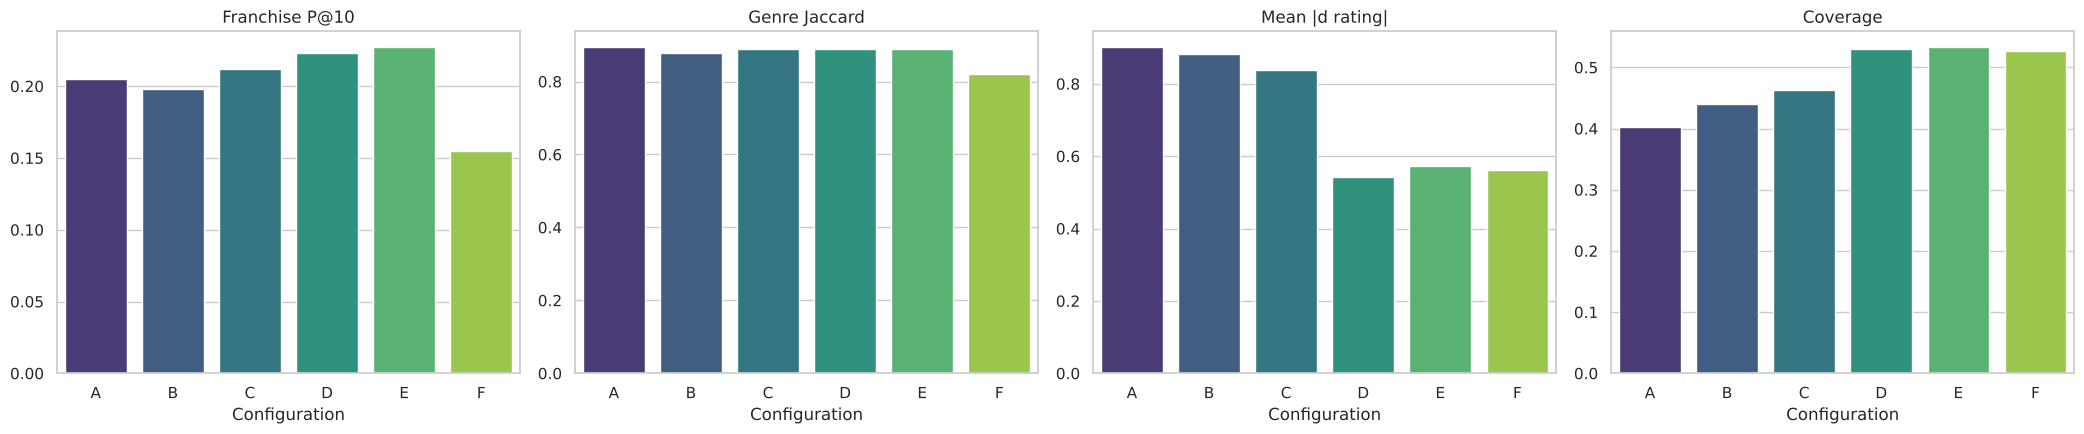

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.5))
short = [n.split("  ")[0] for n in results_df.index]
for ax, col in zip(axes, ["Franchise P@10", "Genre Jaccard", "Mean |d rating|", "Coverage"]):
    sns.barplot(x=short, y=results_df[col].values, ax=ax, palette="viridis")
    ax.set_title(col); ax.set_xlabel("Configuration")
plt.tight_layout(); plt.show()

**Findings**
- **Adding type** (A → C) raises same-type recommendations from 40 % to 73 % — a movie is no longer recommended for a long TV series — and slightly improves franchise precision.
- **Adding rating** (C → D) is the biggest improvement in quality-matching: the average rating gap drops from ≈ 0.84 to ≈ 0.54 and catalogue coverage rises (genre-only lists collapse onto many identical ties).
- **Members + episodes** (D → E) give a further small gain in franchise precision (0.223 → 0.227) and hit-rate (0.416 → 0.429), so **configuration E is the best overall**: it is also the best on the independent franchise metric (P@10 ≈ 0.23 vs 0.21 for genre-only; hit-rate 43 % vs 38 %).
- **TF-IDF genres (B)** did not help: down-weighting common genres is slightly worse than plain multi-hot encoding here.
- **Over-weighting the numeric features (F)** is harmful: same-type reaches 97 %, but genre overlap (Jaccard 0.82) and franchise precision (0.155) fall — the system starts recommending anime that merely *look alike numerically* rather than in content. Genre must stay the dominant signal.

### 8.3 Final configuration
The configuration chosen from the experiment above is used as the final system.

In [17]:
# Configuration E (genre + type + rating + members + episodes) performed best, so it becomes the final system
FINAL_WEIGHTS = dict(w_genre=1.0, w_type=0.5, w_rating=0.5, w_members=0.25, w_episodes=0.25)

In [18]:
X = build_features(**FINAL_WEIGHTS)
final_metrics = pd.Series(evaluate(X, eval_targets))
print("Final system, 1000 random targets, top-10 lists:")
final_metrics.round(3).to_frame("value")

Final system, 1000 random targets, top-10 lists:


,value
Franchise P@10,0.227
Franchise Hit@10,0.429
Genre Jaccard,0.888
Same type,0.733
Mean |d rating|,0.572
Coverage,0.533
Median members of recs,1585.500
n franchise targets,560.000


### 8.4 Qualitative check on well-known titles
Do the recommendations *look* right? We inspect the final system for a few popular franchises.

In [19]:
for q in ["Naruto", "Fullmetal Alchemist: Brotherhood", "Clannad", "Cowboy Bebop"]:
    r = recommend(q, top_n=8)
    print(f"\n=== {r.attrs['target']} ===")
    display(r[["name", "similarity", "genre", "type", "episodes", "rating"]])


=== Naruto ===


,name,similarity,genre,type,episodes,rating
0,Naruto: Shippuuden,0.9994,"Action, Comedy, Martial Arts, Shounen, Super Power",TV,24.0,7.94
1,Boruto: Naruto the Movie,0.9512,"Action, Comedy, Martial Arts, Shounen, Super Power",Movie,1.0,8.03
2,Naruto: Shippuuden Movie 4 - The Lost Tower,0.9512,"Action, Comedy, Martial Arts, Shounen, Super Power",Movie,1.0,7.53
3,Naruto: Shippuuden Movie 3 - Hi no Ishi wo Tsugu Mono,0.9511,"Action, Comedy, Martial Arts, Shounen, Super Power",Movie,1.0,7.50
4,Naruto x UT,0.9509,"Action, Comedy, Martial Arts, Shounen, Super Power",OVA,1.0,7.58
5,Boruto: Naruto the Movie - Naruto ga Hokage ni Natta Hi,0.9508,"Action, Comedy, Martial Arts, Shounen, Super Power",Special,1.0,7.68
6,Naruto Soyokazeden Movie: Naruto to Mashin to Mitsu no O...,0.9507,"Action, Comedy, Martial Arts, Shounen, Super Power",Movie,1.0,7.11
7,Naruto Shippuuden: Sunny Side Battle,0.9505,"Action, Comedy, Martial Arts, Shounen, Super Power",Special,1.0,7.26



=== Fullmetal Alchemist: Brotherhood ===


,name,similarity,genre,type,episodes,rating
0,Fullmetal Alchemist,0.9390,"Action, Adventure, Comedy, Drama, Fantasy, Magic, Milita...",TV,51.0,8.33
1,Fullmetal Alchemist: The Sacred Star of Milos,0.9055,"Action, Adventure, Comedy, Drama, Fantasy, Magic, Milita...",Movie,1.0,7.50
2,Fullmetal Alchemist: Brotherhood Specials,0.8942,"Adventure, Drama, Fantasy, Magic, Military, Shounen",Special,4.0,8.11
3,Magi: The Kingdom of Magic,0.8568,"Action, Adventure, Fantasy, Magic, Shounen",TV,25.0,8.50
4,Magi: The Labyrinth of Magic,0.8567,"Action, Adventure, Fantasy, Magic, Shounen",TV,25.0,8.24
5,Magi: Sinbad no Bouken (TV),0.8563,"Action, Adventure, Fantasy, Magic, Shounen",TV,13.0,8.22
6,Densetsu no Yuusha no Densetsu,0.8563,"Action, Adventure, Fantasy, Magic, Shounen",TV,24.0,7.83
7,Chain Chronicle: Haecceitas no Hikari,0.8545,"Action, Adventure, Fantasy, Magic, Shounen",TV,12.0,6.94



=== Clannad ===


,name,similarity,genre,type,episodes,rating
0,Kokoro Connect,0.9999,"Comedy, Drama, Romance, School, Slice of Life, Supernatural",TV,13.0,8.01
1,Little Busters!: Refrain,0.9998,"Comedy, Drama, Romance, School, Slice of Life, Supernatural",TV,13.0,8.36
2,Kokoro Connect: Michi Random,0.9609,"Comedy, Drama, Romance, School, Slice of Life, Supernatural",Special,4.0,8.19
3,Little Busters!: EX,0.9608,"Comedy, Drama, Romance, School, Slice of Life, Supernatural",Special,8.0,7.94
4,Sakurasou no Pet na Kanojo,0.9195,"Comedy, Drama, Romance, School, Slice of Life",TV,24.0,8.40
5,Chuunibyou demo Koi ga Shitai!,0.9194,"Comedy, Drama, Romance, School, Slice of Life",TV,12.0,7.95
6,Little Busters!,0.9193,"Comedy, Drama, School, Slice of Life, Supernatural",TV,26.0,7.64
7,Chuunibyou demo Koi ga Shitai! Ren,0.9193,"Comedy, Drama, Romance, School, Slice of Life",TV,12.0,7.60



=== Cowboy Bebop ===


,name,similarity,genre,type,episodes,rating
0,Cowboy Bebop: Yose Atsume Blues,0.9598,"Action, Adventure, Comedy, Drama, Sci-Fi, Space",Special,1.0,7.53
1,Seihou Tenshi Angel Links,0.9268,"Action, Adventure, Comedy, Drama, Romance, Sci-Fi, Space",TV,13.0,6.06
2,Seihou Bukyou Outlaw Star,0.9195,"Action, Adventure, Comedy, Sci-Fi, Space",TV,24.0,7.98
3,Ginga Tetsudou Monogatari,0.9185,"Action, Adventure, Drama, Sci-Fi, Space",TV,26.0,7.29
4,Waga Seishun no Arcadia: Mugen Kidou SSX,0.9184,"Action, Adventure, Drama, Sci-Fi, Space",TV,22.0,7.56
5,Ginga Tetsudou Monogatari: Eien e no Bunkiten,0.9179,"Action, Adventure, Drama, Sci-Fi, Space",TV,24.0,7.09
6,Waga Seishun no Arcadia,0.8757,"Action, Adventure, Drama, Sci-Fi, Space",Movie,1.0,7.70
7,Uchuu Kaizoku Captain Harlock: Arcadia-gou no Nazo,0.8750,"Action, Adventure, Drama, Sci-Fi, Space",Movie,1.0,7.18


### 8.5 Bias check: popularity of what gets recommended
Content-based systems can over-recommend a narrow set of titles. We look at how often each anime is recommended across *every* anime's top-10 list.

Catalogue coverage (all anime as targets): 98.3%
Anime never recommended: 204
Top 1% most-recommended anime account for 2.6% of all recommendations


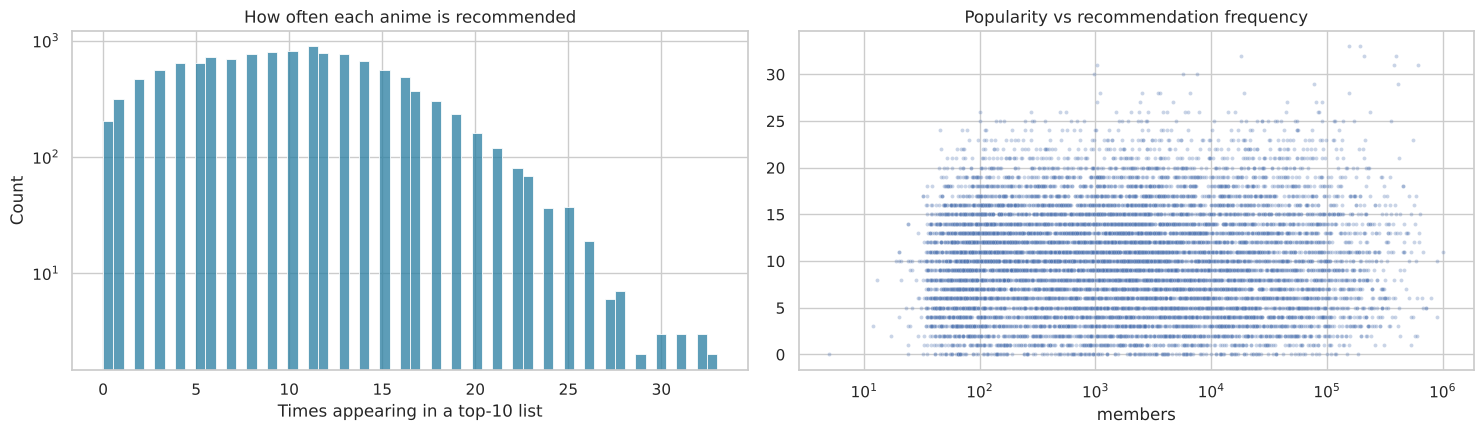


Most frequently recommended anime:


,name,type,rating,members,times_recommended
1093,Saenai Heroine no Sodatekata,TV,7.69,155795,33
1471,Mayo Chiki!,TV,7.53,192219,33
583,Chuunibyou demo Koi ga Shitai!,TV,7.95,394399,32
1275,Chuunibyou demo Koi ga Shitai! Ren,TV,7.60,208885,32
1436,"""Bungaku Shoujo"" Memoire",OVA,7.54,18013,32
158,Sakurasou no Pet na Kanojo,TV,8.40,380375,31
449,Tokyo Ghoul,TV,8.07,618056,31
2737,Yuusha Tokkyuu Might Gaine,TV,7.18,1021,31


In [20]:
all_nbrs = top_k_neighbours(X, np.arange(len(df)), k=10)
rec_counts = np.bincount(all_nbrs.ravel(), minlength=len(df))

print(f"Catalogue coverage (all anime as targets): {(rec_counts > 0).mean():.1%}")
print(f"Anime never recommended: {(rec_counts == 0).sum()}")
print(f"Top 1% most-recommended anime account for {np.sort(rec_counts)[::-1][: len(df)//100].sum() / rec_counts.sum():.1%} of all recommendations")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(rec_counts, bins=60, ax=axes[0], color="#277da1"); axes[0].set_yscale("log")
axes[0].set_title("How often each anime is recommended"); axes[0].set_xlabel("Times appearing in a top-10 list")
sns.scatterplot(x=df["members"], y=rec_counts, s=8, alpha=0.3, ax=axes[1])
axes[1].set_xscale("log"); axes[1].set_title("Popularity vs recommendation frequency"); axes[1].set_xlabel("members")
plt.tight_layout(); plt.show()

print("\nMost frequently recommended anime:")
df.assign(times_recommended=rec_counts).nlargest(8, "times_recommended")[["name", "type", "rating", "members", "times_recommended"]]

### 8.6 Performance summary
- **Content relevance:** recommendations share ≈ 89 % genre overlap (Jaccard) with the target, 73 % have the same broadcast type, and their average rating is within ≈ 0.57 points of the target.
- **Franchise recovery:** although titles are *not* used as a feature, the system places a same-franchise anime in the top-10 for **≈ 43 %** of targets that have one (precision@10 ≈ 0.23). Qualitatively the lists are sensible — *Naruto* → Shippuuden and its movies, *Fullmetal Alchemist: Brotherhood* → the original FMA and similar fantasy-shounen series, *Cowboy Bebop* → space-opera classics.
- **Diversity / bias:** across all 12,232 anime the lists cover **98 %** of the catalogue; the top 1 % of anime account for only ≈ 2.6 % of recommendations and there is no strong tilt towards popular titles (median members of recommended anime ≈ 1,590, close to the catalogue median of ≈ 1,570). The system is therefore not dominated by blockbusters.
- **Weak spots:** only genre, type and three numbers describe an anime, so many titles have *identical* feature vectors and tie (see the best-match histogram above); lists get **crowded by one franchise** (8 of the top-8 for *Naruto* are Naruto/Boruto movies and specials); and a recommendation like *Wind: A Breath of Heart* (rating 6.3) for *Kimi no Na wa.* (9.4) shows that matching genres does not guarantee matching quality.

## 9. Areas for improvement
1. **Richer content features** — add synopsis / tag text with TF-IDF or sentence embeddings, studio, source material, year and characters. Genre alone is coarse and causes ties.
2. **Franchise awareness** — group titles into franchises (sequels, movies, specials) and show them as one entry or rank them first/last, instead of letting them crowd the list (many *Naruto* results are the same franchise).
3. **Quality-aware re-ranking** — rank by `similarity × f(rating, popularity)`, or apply a minimum rating, so that equally similar but poorly rated anime are not shown first.
4. **Diversity (MMR)** — re-rank with Maximal Marginal Relevance so the top-N is not ten near-identical items.
5. **Hybrid with collaborative filtering** — with user–item rating data, blend content similarity with item-based or matrix-factorisation CF to learn personal taste and handle serendipity; keep the content model for **cold-start** (new anime, new users).
6. **Personalisation** — recommend from *several* liked anime (average their feature vectors) rather than a single title.
7. **Better evaluation** — with real user data, use hold-out precision@k / recall@k / NDCG and online A/B tests; the franchise proxy used here is only an approximation.
8. **Tune weights systematically** — grid / Bayesian search over feature weights against an agreed objective, rather than the small manual grid used here.

## 10. Interview questions

### 1. What is the difference between user-based and item-based collaborative filtering?
Both approaches use only the **user–item interaction matrix** (ratings, watches, clicks); they differ in *which similarity* they compute.

| | **User-based CF** | **Item-based CF** |
|---|---|---|
| Idea | "Users who behave like you liked X, so you will too" | "People who liked the items you liked also liked Y" |
| Similarity computed between | **Users** (rows of the matrix) | **Items** (columns of the matrix) |
| Prediction | Weighted average of the ratings that the *most similar users* gave the item | Weighted average of the ratings *you* gave to the items most similar to the target item |
| Scalability | Poor when users ≫ items (millions of users to compare) | Better: the item catalogue is usually smaller and more stable, similarities can be **pre-computed offline** |
| Stability | User tastes drift, so neighbourhoods change often | Item-item relations change slowly |
| Strength | Can give surprising, diverse recommendations (serendipity) | More accurate and easier to explain ("because you watched Death Note") |
| Weakness | Sparsity and new-user cold start; costly | New-item cold start; tends to recommend more "obvious" items |

Example: to recommend an anime to *Asha*, user-based CF finds users whose watch history overlaps hers and recommends what they loved; item-based CF looks at the anime Asha rated highly and recommends the anime most often co-liked with them.

### 2. What is collaborative filtering and how does it work?
**Collaborative filtering (CF)** predicts what a user will like from the **collective behaviour of many users**, without knowing anything about the content of the items. The assumption is that people who agreed in the past tend to agree in the future.

**How it works**
1. **Collect interactions** in a user × item matrix (explicit ratings or implicit signals like views/clicks). The matrix is typically >95 % empty (*sparsity*).
2. **Measure similarity** between users (user-based) or between items (item-based) using cosine similarity, Pearson correlation, etc.
3. **Predict the missing entries** — e.g. for user *u* and item *i*, `r̂(u,i) = mean_u + Σ sim(u,v)·(r(v,i) − mean_v) / Σ|sim(u,v)|` over the nearest neighbours *v* who rated *i*.
4. **Recommend** the unseen items with the highest predicted rating.

**Variants:** *memory-based* (neighbourhood methods above) and *model-based* (matrix factorisation such as SVD/ALS, which learns latent user and item factors, or neural models).

**Pros:** needs no item metadata, discovers unexpected tastes. **Cons:** *cold start* (new users/items have no history), sparsity, popularity bias and scalability.

**Relation to this assignment:** our system is **content-based** (it uses item features: genre, type, rating…). It works for brand-new anime and needs no user data, but cannot learn personal taste. In production the two are usually combined into a **hybrid** recommender.